# 实验四 A 深圳天气的 RNN 与 LSTM 联合预测

用过去若干天的最高/最低气温、天气类别和年周期特征，预测下一天的最高/最低气温及天气类别。比较 RNN、LSTM 在 7 天和 30 天窗口下的表现，并增加“沿用前一天”基线。

原要求的 [ip.cn](https://www.ip.cn/tianqi/guangdong/shenzhen/202603.html) 在本次运行时连接失败，经用户确认，改用 [Open-Meteo Historical API](https://open-meteo.com/en/docs/historical-weather-api) 的 ERA5 再分析数据（深圳 22.55°N、114.05°E；返回网格 22.5°N、114°E），不是气象站逐日实测。固定数据区间为 2024-01-01 至 2026-10-16，共包含 2024、2025 两个完整年份及 2026 部分日期。2026 全年尚未结束，不补造未来观测。

按日期划分：2024 年训练，2025 年验证，2026 年测试。所有预测均为使用已知历史观测的一步预测，不是一次性预测整个未来年度。

In [1]:
from pathlib import Path
import random, json, copy, time, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Dataset

ROOT = Path.cwd() if (Path.cwd() / "exp4").is_dir() else Path.cwd().parent
BASE = ROOT / "exp4"
DATA = BASE / "data"
CACHE = BASE / ".cache" / "exp4A"
RESULT = BASE / "results" / "exp4A"
for folder in [DATA, CACHE, RESULT]:
    folder.mkdir(parents=True, exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
                     "axes.unicode_minus": False, "figure.dpi": 110})
print("Python:", sys.executable, "设备:", device)

Python: D:\Anaconda\python.exe 设备: cpu


## 1 数据清洗与编码

In [2]:
import requests
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, accuracy_score, f1_score, confusion_matrix

url = ("https://archive-api.open-meteo.com/v1/archive?latitude=22.55&longitude=114.05"
       "&start_date=2024-01-01&end_date=2026-10-16"
       "&daily=temperature_2m_max,temperature_2m_min,weather_code&timezone=Asia%2FShanghai&models=era5")
raw_path = DATA / "weather_raw.json"
if not raw_path.exists():
    response = requests.get(url, timeout=90)
    response.raise_for_status()
    raw_path.write_text(json.dumps(response.json(), ensure_ascii=False), encoding="utf-8")
raw = json.loads(raw_path.read_text(encoding="utf-8"))
df = pd.DataFrame(raw["daily"]).rename(columns={"time": "date", "temperature_2m_max": "tmax", "temperature_2m_min": "tmin"})
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates("date").reset_index(drop=True)
assert df["date"].diff().dropna().eq(pd.Timedelta(days=1)).all(), "日期缺失，不能跨缺口拼接窗口"
assert df[["tmax", "tmin", "weather_code"]].notna().all().all(), "源数据缺失，需要先核实"
assert (df.tmax >= df.tmin).all()
# 本次数据实际仅出现 WMO 0~3、51/53/55、61/63/65；按晴云、毛毛雨、降雨三类编码。
def weather_class(code):
    if code <= 3: return 0
    if code in [51,53,55]: return 1
    if code in [61,63,65]: return 2
    raise ValueError(code)
names = ["晴或多云", "毛毛雨", "降雨"]
df["label"] = df.weather_code.astype(int).map(weather_class)
df["weather"] = df.label.map(dict(enumerate(names)))
df["split"] = np.where(df.date.dt.year == 2024, "train", np.where(df.date.dt.year == 2025, "val", "test"))
scaler = StandardScaler().fit(df.loc[df.split == "train", ["tmax", "tmin"]])
temperature = scaler.transform(df[["tmax", "tmin"]]).astype("float32")
day = df.date.dt.dayofyear.to_numpy()
features = np.column_stack([temperature, np.eye(3)[df.label], np.sin(2*np.pi*day/365.25), np.cos(2*np.pi*day/365.25)]).astype("float32")
df.to_csv(RESULT / "weather_clean.csv", index=False, encoding="utf-8-sig")
(RESULT / "data_source.json").write_text(json.dumps({"url": url, "dataset": "ERA5 reanalysis", "request_coordinate": [22.55,114.05], "grid_coordinate": [raw["latitude"],raw["longitude"]], "start": str(df.date.min().date()), "end": str(df.date.max().date()), "rows": len(df), "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist()}, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.crosstab(df.split, df.weather).reindex(["train", "val", "test"], fill_value=0))
print("日期范围:", df.date.min().date(), "至", df.date.max().date(), "总天数:", len(df))

weather,晴或多云,毛毛雨,降雨
split,,,
train,123,137,106
val,126,153,86
test,91,109,89


日期范围: 2024-01-01 至 2026-10-16 总天数: 1020


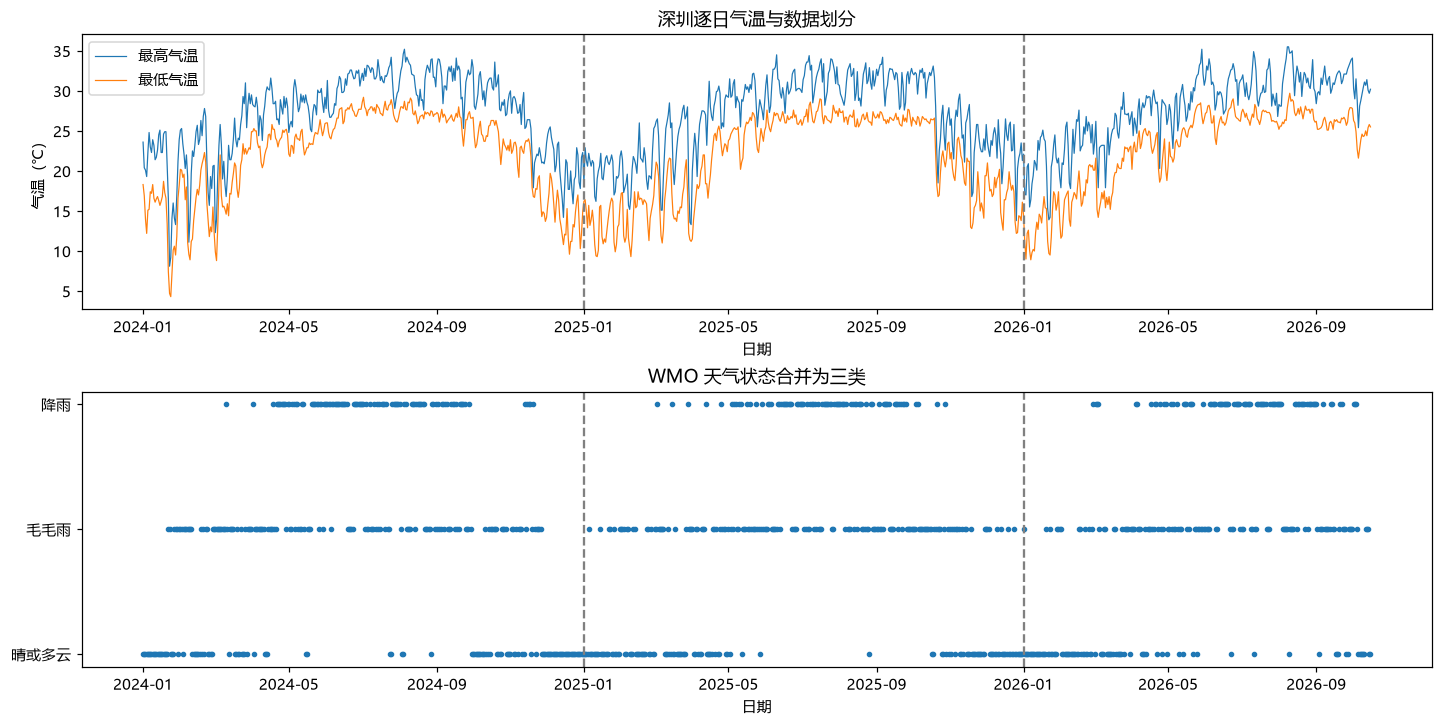

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), constrained_layout=True)
axes[0].plot(df.date, df.tmax, label="最高气温", linewidth=0.8)
axes[0].plot(df.date, df.tmin, label="最低气温", linewidth=0.8)
axes[0].set_ylabel("气温（℃）"); axes[0].set_title("深圳逐日气温与数据划分"); axes[0].legend()
axes[1].scatter(df.date, df.label, s=7)
axes[1].set_yticks(range(3), names); axes[1].set_title("WMO 天气状态合并为三类")
for ax in axes:
    for date in ["2025-01-01", "2026-01-01"]: ax.axvline(pd.Timestamp(date), color="gray", linestyle="--")
    ax.set_xlabel("日期")
fig.savefig(RESULT / "weather_data.png", dpi=180)
plt.show()

## 2 模型与训练

输入维数 7；一层 RNN 或 LSTM，隐藏单元均为 48，取最后时刻输出，分别接 2 维温度回归头和 3 类天气分类头。损失为标准化温度 MSE 加天气交叉熵。Adam 学习率 0.003，batch=32，最多 60 轮，验证损失连续 10 轮未改善时停止，保留验证损失最低的权重。两个窗口均从第 31 天开始取训练目标，保证比较时目标日期完全相同。

归一化仅拟合训练年份。验证与测试窗口可包含其目标日期之前已知的观测，不包含目标当天及之后的观测。

In [4]:
class WeatherNet(nn.Module):
    def __init__(self, kind):
        super().__init__()
        self.sequence = (nn.RNN if kind == "RNN" else nn.LSTM)(7, 48, batch_first=True)
        self.regression = nn.Linear(48, 2)
        self.classification = nn.Linear(48, 3)
    def forward(self, x):
        output, _ = self.sequence(x)
        return self.regression(output[:, -1]), self.classification(output[:, -1])

target_ids = np.arange(30, len(df))
split_ids = {s: target_ids[df.loc[target_ids, "split"].to_numpy() == s] for s in ["train", "val", "test"]}
def loaders_for(window):
    loaders = {}
    for s, ids in split_ids.items():
        x = torch.from_numpy(np.stack([features[i-window:i] for i in ids]))
        y = torch.from_numpy(temperature[ids])
        c = torch.tensor(df.loc[ids, "label"].to_numpy(), dtype=torch.long)
        loaders[s] = DataLoader(TensorDataset(x,y,c), batch_size=32, shuffle=s=="train", num_workers=0,
                                generator=torch.Generator().manual_seed(SEED))
    return loaders

def epoch_weather(model, loader, optimizer=None):
    model.train(optimizer is not None)
    total, sums = 0, np.zeros(3)
    with torch.set_grad_enabled(optimizer is not None):
        for x,y,c in loader:
            x,y,c = x.to(device),y.to(device),c.to(device)
            t, logits = model(x)
            mse = nn.functional.mse_loss(t,y)
            ce = nn.functional.cross_entropy(logits,c)
            loss = mse + ce
            if optimizer is not None:
                optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
            sums += np.array([loss.item(), mse.item(), ce.item()]) * len(x)
            total += len(x)
    return sums/total

metrics, histories, predictions = [], [], {}
test_ids = split_ids["test"]
truth_t = df.loc[test_ids, ["tmax", "tmin"]].to_numpy()
truth_c = df.loc[test_ids, "label"].to_numpy()
def score_weather(name, window, pred_t, pred_c):
    return {"model": name, "window": window, "MAE": mean_absolute_error(truth_t,pred_t),
            "RMSE": np.sqrt(mean_squared_error(truth_t,pred_t)),
            "Accuracy": accuracy_score(truth_c,pred_c),
            "Macro_F1": f1_score(truth_c,pred_c,labels=range(3),average="macro",zero_division=0)}

for window in [7,30]:
    loaders = loaders_for(window)
    for kind in ["RNN", "LSTM"]:
        torch.manual_seed(SEED)
        model = WeatherNet(kind).to(device)
        optimizer = torch.optim.Adam(model.parameters(),lr=0.003)
        best, stale, state, best_epoch = float("inf"), 0, None, 0
        for epoch in range(1,61):
            train = epoch_weather(model,loaders["train"],optimizer)
            val = epoch_weather(model,loaders["val"])
            histories.append(dict(model=kind,window=window,epoch=epoch,train_loss=train[0],val_loss=val[0],train_mse=train[1],val_mse=val[1],train_ce=train[2],val_ce=val[2]))
            if val[0] < best-1e-4:
                best,stale,state,best_epoch = val[0],0,copy.deepcopy(model.state_dict()),epoch
            else: stale += 1
            if stale >= 10: break
        model.load_state_dict(state); model.eval()
        pred_t, pred_c = [], []
        with torch.no_grad():
            for x,_,_ in loaders["test"]:
                t,c = model(x.to(device)); pred_t.extend(t.cpu().numpy()); pred_c.extend(c.argmax(1).cpu().numpy())
        pred_t = scaler.inverse_transform(np.array(pred_t))
        key = f"{kind}_{window}d"
        predictions[key] = (pred_t,np.array(pred_c))
        row = score_weather(kind,window,pred_t,pred_c)
        row.update(best_epoch=best_epoch, parameters=sum(p.numel() for p in model.parameters()))
        metrics.append(row)
        torch.save(state,CACHE/f"{key}.pth")
        print(key, row, flush=True)
baseline_t = df.loc[test_ids-1,["tmax","tmin"]].to_numpy()
baseline_c = df.loc[test_ids-1,"label"].to_numpy()
metrics.append(score_weather("前一天基线",1,baseline_t,baseline_c))
metric_df = pd.DataFrame(metrics)
history_df = pd.DataFrame(histories)
metric_df.to_csv(RESULT/"metrics.csv",index=False,encoding="utf-8-sig")
history_df.to_csv(RESULT/"training_history.csv",index=False)
out = df.loc[test_ids,["date","tmax","tmin","weather"]].copy()
for key,(temps,classes) in predictions.items():
    out[key+"_tmax"],out[key+"_tmin"] = temps[:,0],temps[:,1]
    out[key+"_weather"] = [names[i] for i in classes]
out.to_csv(RESULT/"test_predictions.csv",index=False,encoding="utf-8-sig")
display(metric_df.round(4))

RNN_7d {'model': 'RNN', 'window': 7, 'MAE': 1.1856680144075702, 'RMSE': np.float64(1.568979398465047), 'Accuracy': 0.6262975778546713, 'Macro_F1': 0.6351648351648351, 'best_epoch': 12, 'parameters': 2981}


LSTM_7d {'model': 'LSTM', 'window': 7, 'MAE': 1.1278617165905382, 'RMSE': np.float64(1.515116157910002), 'Accuracy': 0.629757785467128, 'Macro_F1': 0.6388143203785662, 'best_epoch': 22, 'parameters': 11189}


RNN_30d {'model': 'RNN', 'window': 30, 'MAE': 1.1814394436080564, 'RMSE': np.float64(1.5643575464249957), 'Accuracy': 0.6332179930795848, 'Macro_F1': 0.6418443478258369, 'best_epoch': 12, 'parameters': 2981}


LSTM_30d {'model': 'LSTM', 'window': 30, 'MAE': 1.2152482577261212, 'RMSE': np.float64(1.5837325750340874), 'Accuracy': 0.5813148788927336, 'Macro_F1': 0.5888059195249352, 'best_epoch': 16, 'parameters': 11189}


,model,window,MAE,RMSE,Accuracy,Macro_F1,best_epoch,parameters
0,RNN,7,1.1857,1.5690,0.6263,0.6352,12.0,2981.0
1,LSTM,7,1.1279,1.5151,0.6298,0.6388,22.0,11189.0
2,RNN,30,1.1814,1.5644,0.6332,0.6418,12.0,2981.0
3,LSTM,30,1.2152,1.5837,0.5813,0.5888,16.0,11189.0
4,前一天基线,1,1.1701,1.6306,0.6263,0.6330,NaN,NaN


## 3 损失曲线与独立测试结果

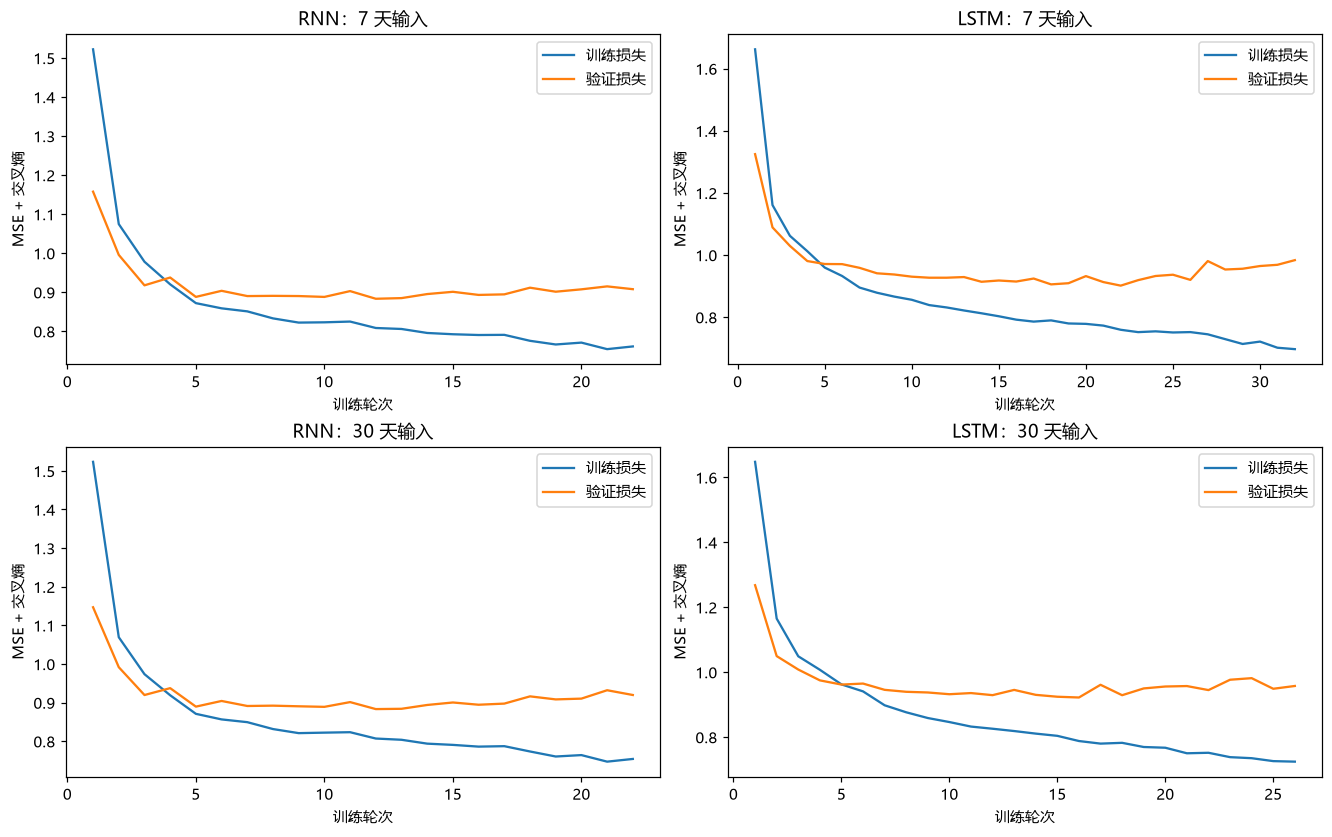

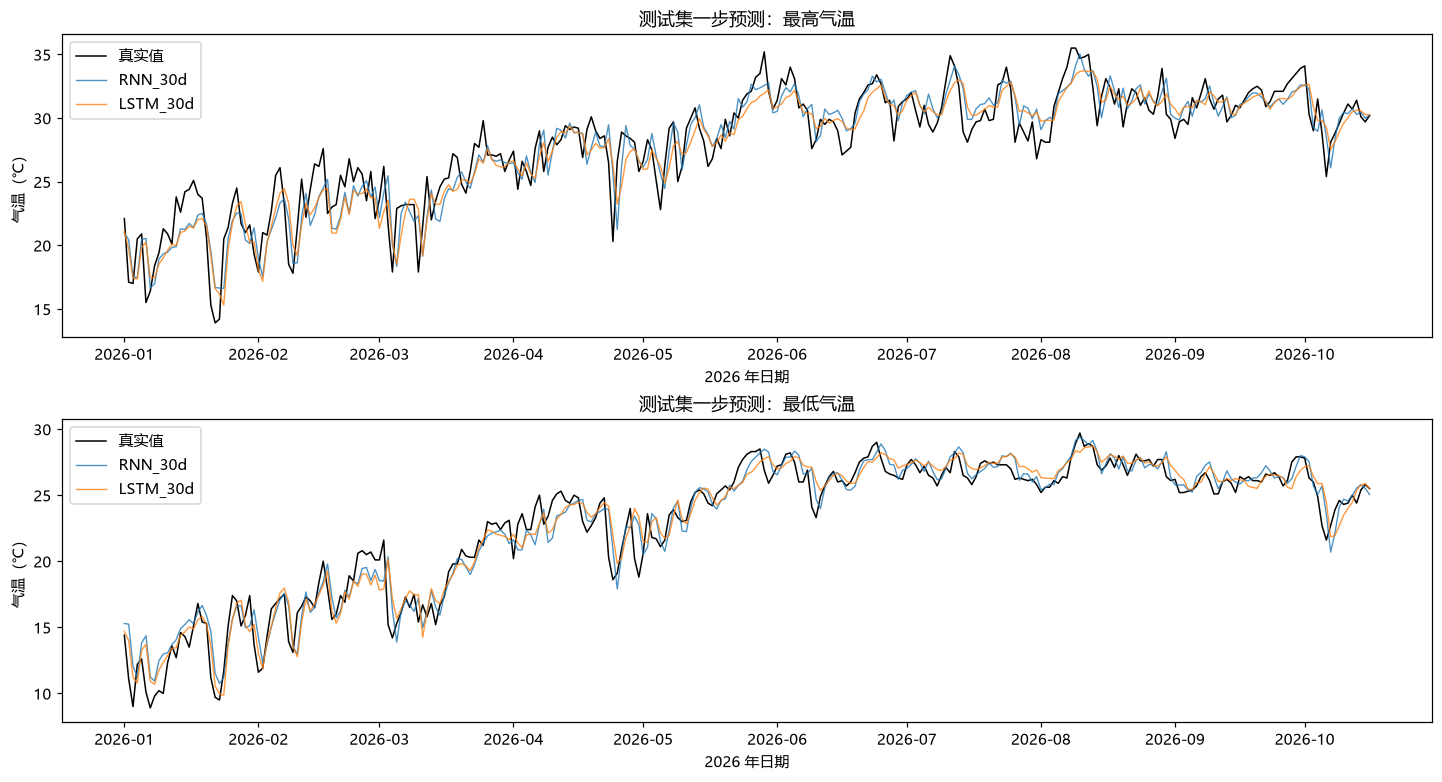

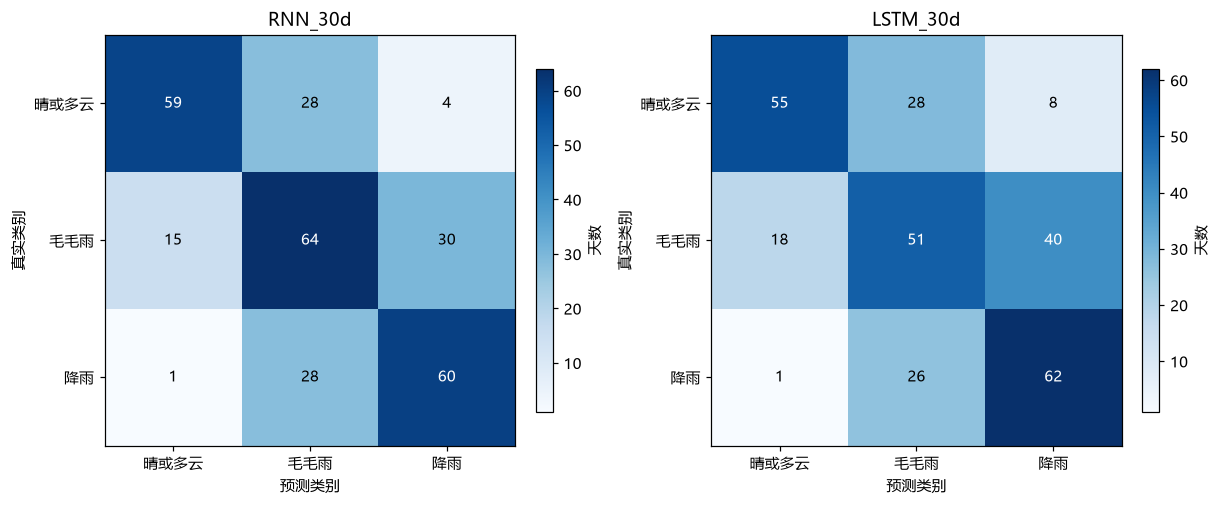

所有模型的测试目标日期相同： 289 天。
天气各类支持数： {'晴或多云': np.int64(91), '毛毛雨': np.int64(109), '降雨': np.int64(89)}


In [5]:
fig, axes = plt.subplots(2,2,figsize=(12,7.5),constrained_layout=True)
for ax,((kind,window),part) in zip(axes.flat,history_df.groupby(["model","window"],sort=False)):
    ax.plot(part.epoch,part.train_loss,label="训练损失")
    ax.plot(part.epoch,part.val_loss,label="验证损失")
    ax.set(title=f"{kind}：{window} 天输入",xlabel="训练轮次",ylabel="MSE + 交叉熵");ax.legend()
fig.savefig(RESULT/"training_curves.png",dpi=180);plt.show()

fig, axes=plt.subplots(2,1,figsize=(13,7),constrained_layout=True)
for k,label in enumerate(["最高气温","最低气温"]):
    axes[k].plot(df.loc[test_ids,"date"],truth_t[:,k],label="真实值",color="black",linewidth=1)
    for key in ["RNN_30d","LSTM_30d"]:
        axes[k].plot(df.loc[test_ids,"date"],predictions[key][0][:,k],label=key,alpha=0.8,linewidth=0.9)
    axes[k].set(title=f"测试集一步预测：{label}",xlabel="2026 年日期",ylabel="气温（℃）");axes[k].legend()
fig.savefig(RESULT/"temperature_predictions.png",dpi=180);plt.show()

fig, axes=plt.subplots(1,2,figsize=(11,4.7),constrained_layout=True)
for ax,key in zip(axes,["RNN_30d","LSTM_30d"]):
    cm=confusion_matrix(truth_c,predictions[key][1],labels=range(3))
    im=ax.imshow(cm,cmap="Blues")
    ax.set(xticks=range(3),yticks=range(3),xticklabels=names,yticklabels=names,xlabel="预测类别",ylabel="真实类别",title=key)
    for i in range(3):
        for j in range(3): ax.text(j,i,str(cm[i,j]),ha="center",va="center",color="white" if cm[i,j]>cm.max()/2 else "black")
    fig.colorbar(im,ax=ax,shrink=0.7,label="天数")
fig.savefig(RESULT/"weather_confusion.png",dpi=180);plt.show()
print("所有模型的测试目标日期相同：",len(test_ids),"天。")
print("天气各类支持数：",dict(zip(names,np.bincount(truth_c,minlength=3))))

## 分析依据与限制

根据 metrics.csv 比较同一窗口下 RNN 与 LSTM 的 MAE、RMSE 和宏平均 F1，再比较 7 天和 30 天窗口。LSTM 的门控机制有利于保留长期信息，但本实验的天气、样本量及训练结果不保证 LSTM 必定优于 RNN；若不及前一天基线，应如实说明。宏平均 F1 按实际建模的三类计算，不能把准确率当作所有天气类型的识别能力。本次 ERA5 数据没有雾、雪或雷暴编码，模型不评估这些状态。

长窗口只覆盖 30 天，无法据此证明年度尺度的长期依赖建模能力。ERA5 有空间网格和平滑误差；结果只适用于本数据区间和逐日滚动一步评估。模型没有接入气压、湿度和卫星等信息，不构成实际气象预报系统。

本次输出中，7 天 LSTM 的温度 MAE 为 1.1279℃、RMSE 为 1.5151℃，天气准确率为 0.6298、宏平均 F1 为 0.6388。30 天 RNN 的宏平均 F1 为 0.6418，30 天 LSTM 降至 0.5888。前一天基线 MAE 为 1.1701℃，因此短窗口 LSTM 改善了温度误差，但更长窗口与门控结构没有带来一致提升。这里温度指标合并最高与最低气温两维误差计算；天气指标为三类，样本量和年际分布变化限制了结论。